# Gate selection

ASPIRE scores a pair of sites by the removable quantum mutual information $R_{ij}$, the largest decrease of the total correlation $T=\sum_a S(\rho_a)$ that one two-qubit gate on $(i,j)$ can achieve. This notebook checks the closed form of $R_{ij}$, compares layer selectors, shows the effect of the thresholds, and checks that the drop of $T$ is additive over a layer. Entropies are in bits.

In [1]:
using Pkg; Pkg.activate(@__DIR__)

In [2]:
using ASPIRE, Plots, Random, LinearAlgebra
using ITensorMPS: siteinds, maxlinkdim

set_max_bond_dim!(64)
default(framestyle = :box, linewidth = 2, markersize = 5, guidefontsize = 10, titlefontsize = 10,
        left_margin = 4Plots.mm, bottom_margin = 4Plots.mm)
const ORANGE, GREY = "#ff7f0e", "#555555"

heis = heisenberg_snake_state(4, 3; nsweeps = 8, maxdim = [8, 16, 32], rng = MersenneTwister(1))

# All two-site marginals of a state as dense 4x4 matrices (site i is the more significant qubit)
function pair_marginals(psi)
    s = siteinds(psi)
    rdms = all_pairs_two_site_rdms(psi, candidate_pairs(length(psi)))
    return Dict(p => Matrix{ComplexF64}(dense_two_site_matrix(rho, s, p[1], p[2])) for (p, rho) in rdms)
end
marg = pair_marginals(heis)
N = length(heis)

12

Closed-form removable correlation of a two-qubit state against a numerical minimisation over unitaries (3000 Haar-random unitaries followed by 3000 local perturbation steps), for random density matrices of rank 2, 3 and 4. The search can only overestimate the minimum, so it should not exceed the closed form.

In [3]:
h2(p) = (p <= 0 || p >= 1) ? 0.0 : -p * log2(p) - (1 - p) * log2(1 - p)
lmax(sigma) = maximum(real.(eigvals(Hermitian(sigma))))

function closed_form_R(rho)
    p = sort(real.(eigvals(Hermitian(rho))); rev = true)
    mu_i = 1 - lmax(marginal(rho, 2, 1))
    mu_j = 1 - lmax(marginal(rho, 2, 2))
    return h2(mu_i) + h2(mu_j) - h2(p[2] + p[4]) - h2(p[3] + p[4])
end

marginal_entropy_sum(rho) = von_neumann_entropy(marginal(rho, 2, 1)) + von_neumann_entropy(marginal(rho, 2, 2))

function search_R(rho, rng; nsamples = 3000, nlocal = 3000)
    base = marginal_entropy_sum(rho)
    best, Ubest = Inf, Matrix{ComplexF64}(I, 4, 4)
    for _ in 1:nsamples
        U = haar_unitary(4, rng)
        v = marginal_entropy_sum(U * rho * U')
        v < best && ((best, Ubest) = (v, U))
    end
    eta = 0.3
    for _ in 1:nlocal
        H = randn(rng, ComplexF64, 4, 4); H = (H + H') / 2
        V = exp(im * eta * H) * Ubest
        v = marginal_entropy_sum(V * rho * V')
        if v < best
            best, Ubest = v, V
        else
            eta = max(eta * 0.999, 1e-4)
        end
    end
    return base - best
end

function random_state(rng; rank)
    A = randn(rng, ComplexF64, 4, rank) .* reshape(exp.(-2 .* rand(rng, rank) .* (0:rank-1)), 1, rank)
    rho = A * A'
    return rho ./ real(tr(rho))
end

rng = MersenneTwister(7)
test_states = [random_state(rng; rank = r) for r in repeat([2, 3, 4], 8)]
closed = closed_form_R.(test_states)
package = removable_mutual_information.(test_states)
search = [search_R(rho, MersenneTwister(100 + k)) for (k, rho) in enumerate(test_states)]

println("max |closed form - package|      = ", maximum(abs.(closed .- package)))
println("max (search - closed form)       = ", maximum(search .- closed))
println("max (closed form - search)       = ", maximum(closed .- search))

max |closed form - package|      = 8.215650382226158e-15
max (search - closed form)       = -3.696512412637576e-5
max (closed form - search)       = 0.004738878806170188


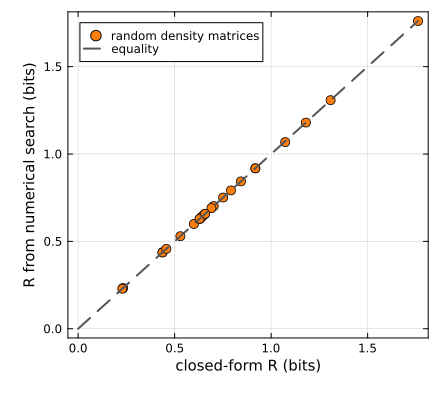

In [4]:
scatter(closed, search; color = ORANGE, label = "random density matrices",
        xlabel = "closed-form R (bits)", ylabel = "R from numerical search (bits)",
        legend = :topleft, size = (440, 400))
plot!([0, maximum(closed)], [0, maximum(closed)]; color = GREY, linestyle = :dash, label = "equality")

One layer of the Heisenberg state selected by branch-and-bound matching and by the blossom algorithm (both on the 32 best pairs, and blossom on all pairs), and by the greedy rule that skips pairs coupled to chosen ones by more than 0.1 bits.

In [5]:
Imat(rho) = max(0.0, quantum_mutual_information(rho))
pairs = candidate_pairs(N)
R = Dict(p => removable_mutual_information(marg[p]) for p in pairs)
I = Dict(p => Imat(marg[p]) for p in pairs)
score = Dict(p => R[p] for p in pairs if R[p] > 0)

top32 = first(sort(collect(keys(score)); by = p -> -score[p]), 32)
branch_and_bound = maximum_weight_pair_matching(top32, score; max_edges = 48)
blossom_32 = select_layer(Dict(p => score[p] for p in top32))
blossom_all = select_layer(score)
greedy = mincut_batch(pairs, R; couple = (a, b) -> I[minmax(a, b)], rank_threshold = 0.0, couple_threshold = 0.1)

selections = ["branch and bound, 32 pairs" => branch_and_bound, "blossom, 32 pairs" => blossom_32,
              "blossom, all pairs" => blossom_all, "greedy, kappa = 0.1" => greedy]
for (name, sel) in selections
    println(rpad(name, 28), "gates = ", length(sel), "   total R = ", round(matching_weight(sel, R), digits = 6), " bits")
end

cfg = ASPIREConfig(threshold = 0.0, relative_threshold = 0.0, cost_normalised = false, batch_mode = :matching, shortlist = 32)
step = aspire_step(heis; config = cfg)
println("aspire_step proposes ", length(step.proposed), " gates with total R = ", round(matching_weight(step.proposed, R), digits = 6), " bits")

branch and bound, 32 pairs  gates = 6   total R = 3.440326 bits
blossom, 32 pairs           gates = 6   total R = 3.440326 bits
blossom, all pairs          gates = 6   total R = 3.440326 bits
greedy, kappa = 0.1         gates = 2   total R = 1.365681 bits
aspire_step proposes 6 gates with total R = 3.440326 bits


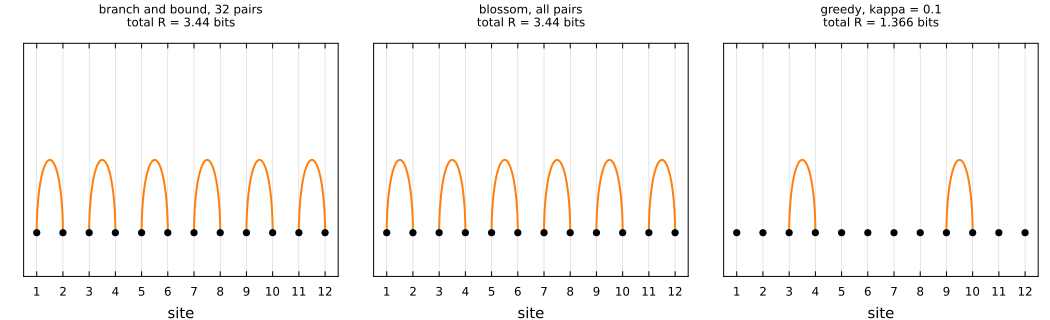

In [6]:
ymax = maximum((j - i) / 2 for (_, sel) in selections for (i, j) in sel) + 0.8
function arcs(sel, N; title)
    plt = plot(; xlims = (0.5, N + 0.5), ylims = (-0.3, ymax), top_margin = 6Plots.mm, legend = false, yticks = false, xticks = 1:N,
               xlabel = "site", title = title)
    t = range(0, pi; length = 60)
    for (i, j) in sel
        plot!(plt, (i + j) / 2 .+ (j - i) / 2 .* cos.(t), (j - i) / 2 .* sin.(t); color = ORANGE, linewidth = 2)
    end
    scatter!(plt, 1:N, zeros(N); color = :black, markersize = 4)
    return plt
end
plot([arcs(sel, N; title = "$(name)\ntotal R = $(round(matching_weight(sel, R), digits = 3)) bits") for (name, sel) in selections[[1, 3, 4]]]...;
     layout = (1, 3), size = (1050, 320), titlefontsize = 8)

Thresholds. A pair is admitted when its score per native gate, $R_{ij}/3$, is at least $\max(\tau,\ \rho\max_{kl}R_{kl}/3)$. The panels show the number of admitted pairs and the total $R$ of the blossom layer built from them.

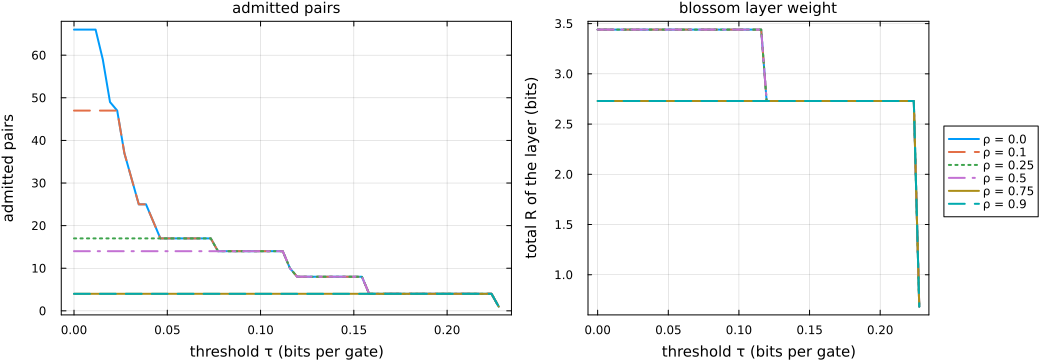

In [7]:
sc = Dict(p => R[p] / 3 for p in pairs)
taus = range(0, maximum(values(sc)); length = 60)
rhos = [0.0, 0.1, 0.25, 0.5, 0.75, 0.9]

function admitted(tau, rho)
    floor_ = aspire_rank_threshold(values(sc); threshold = tau, relative_threshold = rho)
    return [p for p in pairs if sc[p] > 0 && sc[p] >= floor_]
end
layer_weight(adm) = isempty(adm) ? 0.0 : matching_weight(select_layer(Dict(p => R[p] for p in adm)), R)

p1 = plot(; xlabel = "threshold τ (bits per gate)", ylabel = "admitted pairs", legend = false, title = "admitted pairs")
p2 = plot(; xlabel = "threshold τ (bits per gate)", ylabel = "total R of the layer (bits)", legend = :outerright, title = "blossom layer weight")
styles = [:solid, :dash, :dot, :dashdot, :solid, :dash]
for (rho, ls) in zip(rhos, styles)
    adm = [admitted(t, rho) for t in taus]
    plot!(p1, taus, length.(adm); label = "ρ = $rho", linewidth = 2, linestyle = ls)
    plot!(p2, taus, layer_weight.(adm); label = "ρ = $rho", linewidth = 2, linestyle = ls)
end
plot(p1, p2; layout = (1, 2), size = (1050, 360))

Additivity. Six blossom layers are applied to the Heisenberg state, each gate being the eigenbasis gate of its pair computed from the pre-layer state. The realised drop of $T$ over a layer is compared with the sum of $R_{ij}$, and each gate applied alone is compared with its own $R_{ij}$.

In [8]:
function additivity_run(psi; layers = 6)
    rows = NamedTuple[]
    worst_single = 0.0
    for layer in 1:layers
        m = pair_marginals(psi)
        Rl = Dict(p => removable_mutual_information(r) for (p, r) in m)
        sel = select_layer(Dict(p => w for (p, w) in Rl if w > 1e-9))
        isempty(sel) && break
        gates = Dict(p => eigenbasis_gate(m[p]) for p in sel)
        T0 = total_correlation(psi)
        for p in sel
            alone = apply_two_qubit_unitary(psi, p[1], p[2], gates[p])
            worst_single = max(worst_single, abs((T0 - total_correlation(alone)) - Rl[p]))
        end
        after = psi
        for p in sel
            after = apply_two_qubit_unitary(after, p[1], p[2], gates[p])
        end
        T1 = total_correlation(after)
        push!(rows, (layer = layer, gates = length(sel), predicted = sum(Rl[p] for p in sel), realised = T0 - T1,
                     T = T1, Lambda = lambda_certificate(after)))
        psi = after
    end
    return rows, worst_single
end

rows, worst_single = additivity_run(heis)
println("layer  gates  sum of R_ij   realised drop of T   Lambda     T/2")
for r in rows
    println(lpad(r.layer, 5), lpad(r.gates, 7), lpad(round(r.predicted, digits = 8), 14), lpad(round(r.realised, digits = 8), 21),
            lpad(round(r.Lambda, digits = 5), 11), lpad(round(r.T / 2, digits = 5), 10))
end
println("max |realised - predicted| per layer : ", maximum(abs(r.realised - r.predicted) for r in rows))
println("max |single-gate drop - R_ij|        : ", worst_single)

layer  gates  sum of R_ij   realised drop of T   Lambda     T/2
    1      6    3.44032632           3.44032632    2.39225   4.27984
    2      6    1.35280525           1.35280525     1.8201   3.60343
    3      6     1.2989649            1.2989649    1.38472   2.95395
    4      6    0.43277221           0.43277221     1.2108   2.73757
    5      6    0.40177184           0.40177184    1.07899   2.53668
    6      6    0.75099862           0.75099862     0.8855   2.16118
max |realised - predicted| per layer : 2.172861890414879e-11
max |single-gate drop - R_ij|        : 1.7466250668007888e-11


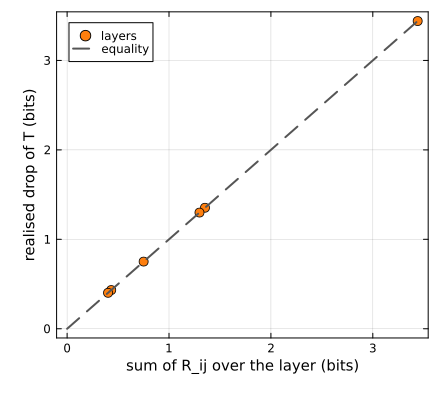

In [9]:
pred = [r.predicted for r in rows]; real_ = [r.realised for r in rows]
scatter(pred, real_; color = ORANGE, label = "layers", xlabel = "sum of R_ij over the layer (bits)",
        ylabel = "realised drop of T (bits)", legend = :topleft, size = (440, 400))
plot!([0, maximum(pred)], [0, maximum(pred)]; color = GREY, linestyle = :dash, label = "equality")